# EDA de COVID-19 nos Estados Unidos — nível médio

**Projeto de Fabiana · roteiro de estudo em português**

EDA significa **análise exploratória de dados**. Antes de prever ou explicar um fenômeno, precisamos descobrir o que a tabela contém, quais problemas existem e o que os dados permitem afirmar.

Imagine o pedido do cliente: “Organize estes dados e me conte o que aconteceu”. A entrega tem duas linguagens: este notebook registra o raciocínio técnico; o relatório de duas páginas apresenta as conclusões para quem não programa.

**Como estudar:** leia o texto, execute apenas a célula seguinte com **Shift + Enter**, observe a saída e leia sua interpretação. As células compartilham variáveis: execute na ordem. Ao terminar, reinicie o kernel e execute tudo para verificar a reprodução.

**Roteiro:** 1. entender o pedido; 2. preparar ferramentas; 3. carregar; 4. inspecionar; 5. limpar; 6. criar variáveis; 7. estudar uma variável; 8. investigar outliers; 9. agrupar; 10. relacionar variáveis; 11. estudar o tempo; 12. analisar correlações; 13. responder; 14. gerar o relatório.

Os dados são históricos; a coleta terminou em **7 de março de 2021**. Não descrevem a situação atual.

## 1. Ler o enunciado e transformar o pedido em perguntas

O [enunciado original](../docs/enunciado.md) dá uma semana e permite escolher o dataset. Escolhemos a fonte sugerida, o COVID Tracking Project, e o **nível médio**, que inclui todos os requisitos essenciais.

| O enunciado pede | O que faremos |
|---|---|
| Entender a estrutura | shape, info, head e describe |
| Limpar e justificar | Duplicados, tipos, nulos, seleção e renomeação |
| Três variáveis separadas | Casos acumulados, estado e óbitos acumulados |
| Três relações | Estado × casos, casos × óbitos, data × incrementos |
| Pelo menos cinco gráficos | Histogramas, barras, boxplot, dispersão, linhas e heatmaps |
| Três perguntas respondidas | As perguntas abaixo, com números calculados |
| Outliers | Regra do intervalo interquartil e decisão documentada |
| groupby, agg e pivot_table | Resumos por estado, dia e mês |
| Pelo menos três variáveis novas | Ano, mês, dia da semana e indicadores de correção |
| Correlação e tempo | Heatmap e séries diárias |
| Relatório de 1 a 2 páginas | PDF com conclusões, gráficos e limitações |

### Perguntas formuladas antes da análise

1. **Como evoluíram os registros diários de casos e óbitos?** Em que datas ocorreram os maiores incrementos líquidos registrados?
2. **Quais estados ou territórios concentraram mais casos acumulados na mesma data final?**
3. **Existe associação entre casos e óbitos acumulados entre as jurisdições nessa data?**
4. **Que problemas de qualidade limitam a interpretação, especialmente das hospitalizações?**

**Hipóteses para investigar, não conclusões:** a série pode apresentar ondas; os totais podem se concentrar em poucas jurisdições; casos e óbitos podem variar juntos. Vamos conferir, não assumir.

Não há população neste dataset. Portanto, “mais casos acumulados” significa **maior volume registrado**, e não necessariamente maior risco por habitante.

### 1.1. Entender o que representa uma linha

Cada linha representa **um estado ou território em uma data de coleta**. A chave natural é o par **estado + data**. As 56 jurisdições incluem estados, o Distrito de Colúmbia e territórios; não são 56 estados.

| Conceito | Exemplo simples | Consequência |
|---|---|---|
| Acumulado | 100 casos ontem, 110 hoje | Não somar 100 + 110 para dizer que houve 210 casos |
| Incremento diário | 110 − 100 = 10 | Pode ser somado entre datas, respeitando revisões e cobertura |
| Medida do momento | 20 pessoas hospitalizadas hoje | Somar dias não produz o número de pessoas únicas hospitalizadas |
| Nulo | O estado não informou um valor | Não equivale a zero |
| Correção negativa | O acumulado foi revisto de 110 para 108 | O incremento de −2 é uma revisão; não são “casos negativos” |

A data é de **coleta/notificação**, não necessariamente a data da infecção ou do óbito. Um pico pode refletir notificações atrasadas.

Fontes: [download oficial](https://covidtracking.com/data/download/) e [definições oficiais](https://covidtracking.com/about-data/data-definitions/).

## 2. Preparar as ferramentas

Para usar **Google Colab dentro do VS Code**, instale a extensão oficial **Colab**, do Google, e **Jupyter**, da Microsoft. Abra **Select Kernel → Colab → Auto Connect** e entre com sua conta Google. Este EDA pode usar CPU.

Depois de conectar, clique com o botão direito na pasta **scripts** do Explorer e escolha **Upload to Colab**. No painel **Colab → Contents**, confira se existem `/content/scripts/baixar_dados.py` e `/content/scripts/gerar_relatorio.py`. O notebook usa esses dois arquivos; o CSV será baixado automaticamente. Repita o envio ao conectar a um servidor novo.

No Colab, as bibliotecas e os arquivos gerados ficam no servidor remoto. Se faltar uma biblioteca, execute `%pip install pandas numpy matplotlib seaborn requests` em uma célula temporária, reinicie o kernel e execute novamente. Salve o notebook com **Cmd + S** para guardar suas saídas; para preservar também o PDF, as tabelas e os dados, siga as instruções de Google Drive no [README](../README.md#google-colab-dentro-do-vs-code).

**Alternativa local:** um ambiente virtual separa as bibliotecas deste projeto. Execute **bash scripts/preparar_ambiente.sh** no terminal e selecione o Python de **.venv** em **Select Kernel**.

Na célula abaixo, **import** carrega ferramentas; **as** cria um apelido. pandas (pd) trabalha com tabelas; numpy (np), com cálculos; matplotlib (plt) e seaborn (sns), com gráficos. Path representa caminhos de arquivos.


In [1]:
from pathlib import Path
import os
import sys

# Procura o projeto local ou os scripts enviados ao servidor Colab.
candidatos = [
    Path.cwd(), *Path.cwd().parents,
    Path("/content"), Path("/content/ai_project_EDA"),
]
ROOT = next(
    (p for p in candidatos
     if (p / "scripts/baixar_dados.py").is_file()
     and (p / "scripts/gerar_relatorio.py").is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError(
        "Pasta scripts não encontrada. No Colab pelo VS Code, clique com o "
        "botão direito na pasta scripts e escolha Upload to Colab. "
        "Confira os dois arquivos .py em /content/scripts. "
        "No Python local, abra o notebook dentro da pasta do projeto."
    )
os.environ.setdefault("MPLCONFIGDIR", str(ROOT / ".cache/matplotlib"))
sys.path.insert(0, str(ROOT / "scripts"))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown
from baixar_dados import baixar_dados

sns.set_theme(style="whitegrid", palette="colorblind")
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
print("Pasta do projeto:", ROOT)
print("Python:", sys.version.split()[0], "| pandas:", pd.__version__)

Pasta do projeto: /private/tmp/eda-entrega-20261109-6nys_e8j
Python: 3.14.6 | pandas: 3.1.0


### 2.1. Separar entrada e saída

**raw** guarda o arquivo recebido; **processed**, a tabela preparada. Os resultados ficam em **reports**. Essa organização permite voltar à fonte e explicar qualquer transformação.

A pequena função abaixo somente salva figuras. O argumento fig é o gráfico criado; nome é o nome do arquivo PNG. Os dados e cálculos continuam visíveis nas próximas células.

In [2]:
PROCESSED = ROOT / "data/processed"
FIGURES = ROOT / "reports/figures"
TABLES = ROOT / "reports/tables"
for pasta in [PROCESSED, FIGURES, TABLES]:
    pasta.mkdir(parents=True, exist_ok=True)

def salvar_figura(fig, nome):
    fig.tight_layout()
    fig.savefig(FIGURES / nome, dpi=160, bbox_inches="tight")
    plt.show()

## 3. Carregar os dados oficiais

**CSV** é um arquivo de texto que organiza linhas e colunas. **DataFrame** é a tabela em memória com que o pandas trabalha.

A função baixar_dados usa o CSV local se ele existir; só acessa a internet na primeira execução. Ela confere a resposta do servidor e registra endereço, data de download e hash em data/raw/covid_us.metadata.json.

**df_bruto** preserva a entrada. Mais adiante criaremos outra tabela para a limpeza. Assim evitamos confundir o que veio da fonte com o que transformamos.

In [3]:
arquivo = baixar_dados()
df_bruto = pd.read_csv(arquivo)
print("Arquivo carregado:", arquivo.name)

Usando o arquivo local: /private/tmp/eda-entrega-20261109-6nys_e8j/data/raw/covid_us.csv
Arquivo carregado: covid_us.csv


## 4. Investigar antes de modificar

### 4.1. Dimensão: shape

**shape** retorna uma dupla: primeiro o número de linhas, depois o de colunas. Cada coluna é uma variável; cada linha, uma observação. Não são necessários parênteses porque shape é uma propriedade, não uma função.

In [4]:
linhas, colunas = df_bruto.shape
print(f"Linhas: {linhas:,} | Colunas: {colunas}")
print("Jurisdições:", df_bruto["state"].nunique())

Linhas: 20,780 | Colunas: 56
Jurisdições: 56


### 4.2. Primeiras linhas: head

**head(5)** mostra cinco linhas. Isso ajuda a reconhecer nomes, formatos e exemplos, mas não representa necessariamente a distribuição inteira. A fonte pode vir ordenada da data mais recente para a mais antiga.

In [5]:
display(df_bruto.head(5))

,date,state,positive,probableCases,negative,pending,totalTestResultsSource,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,...,dataQualityGrade,deathIncrease,hospitalizedIncrease,hash,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
0,20210307,AK,"56,886.00",NaN,NaN,NaN,totalTestsViral,"1,731,628.00",33.00,"1,293.00",...,NaN,0,0,dc4bccd4bb885349d7e94d6fed058e285d4be164,0,0,0,0,0,NaN
1,20210307,AL,"499,819.00","107,742.00","1,931,711.00",NaN,totalTestsPeopleViral,"2,323,788.00",494.00,"45,976.00",...,NaN,-1,0,997207b430824ea40b8eb8506c19a93e07bc972e,0,0,0,0,0,NaN
2,20210307,AR,"324,818.00","69,092.00","2,480,716.00",NaN,totalTestsViral,"2,736,442.00",335.00,"14,926.00",...,NaN,22,11,50921aeefba3e30d31623aa495b47fb2ecc72fae,0,0,0,0,0,NaN
3,20210307,AS,0.00,NaN,"2,140.00",NaN,totalTestsViral,"2,140.00",NaN,NaN,...,NaN,0,0,f77912d0b80d579fbb6202fa1a90554fc4dc1443,0,0,0,0,0,NaN
4,20210307,AZ,"826,454.00","56,519.00","3,073,010.00",NaN,totalTestsViral,"7,908,105.00",963.00,"57,907.00",...,NaN,5,44,0437a7a96f4471666f775e63e86923eb5cbd8cdf,0,0,0,0,0,NaN


### 4.3. Tipos e preenchimento: info

**info()** informa tipos e quantidades não nulas. int/float representam números; str/object, texto. Uma coluna numérica pode aparecer como float porque contém nulos.

Observe date: um número como 20210307 parece numérico, mas significa 7 de março de 2021. Fazer a média desses números não é uma análise de datas.

In [6]:
df_bruto.info()

<class 'pandas.DataFrame'>
RangeIndex: 20780 entries, 0 to 20779
Data columns (total 56 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   date                         20780 non-null  int64  
 1   state                        20780 non-null  str    
 2   positive                     20592 non-null  float64
 3   probableCases                9271 non-null   float64
 4   negative                     13290 non-null  float64
 5   pending                      2138 non-null   float64
 6   totalTestResultsSource       20780 non-null  str    
 7   totalTestResults             20614 non-null  float64
 8   hospitalizedCurrently        17339 non-null  float64
 9   hospitalizedCumulative       12382 non-null  float64
 10  inIcuCurrently               11636 non-null  float64
 11  inIcuCumulative              3789 non-null   float64
 12  onVentilatorCurrently        9126 non-null   float64
 13  onVentilatorCumulative     

### 4.4. Resumo numérico: describe

**count** conta valores conhecidos; **mean** é a média; **std**, o desvio padrão; **min/max**, extremos. Os percentis 25%, 50% e 75% dividem os dados ordenados; 50% é a mediana.

Nesta inspeção misturamos estados e datas. O resumo serve para detectar ordens de grandeza e possíveis problemas. Para comparar estados, usaremos mais adiante uma mesma data.

In [7]:
display(df_bruto.describe())

,date,positive,probableCases,negative,pending,totalTestResults,hospitalizedCurrently,hospitalizedCumulative,inIcuCurrently,inIcuCumulative,...,posNeg,dataQualityGrade,deathIncrease,hospitalizedIncrease,commercialScore,negativeRegularScore,negativeScore,positiveScore,score,grade
count,"20,780.00","20,592.00","9,271.00","13,290.00","2,138.00","20,614.00","17,339.00","12,382.00","11,636.00","3,789.00",...,"20,780.00",0.00,"20,780.00","20,780.00","20,780.00","20,780.00","20,780.00","20,780.00","20,780.00",0.00
mean,"20,202,440.02","165,155.97","21,729.12","848,224.62","1,659.86","2,186,935.75","1,190.58","9,262.76",359.62,"1,934.19",...,"706,150.00",NaN,24.79,37.36,0.00,0.00,0.00,0.00,0.00,NaN
std,"3,608.73","326,785.24","45,471.46","1,344,501.36","4,671.03","4,436,508.15","2,060.04","12,620.54",594.83,"1,953.33",...,"1,299,996.54",NaN,60.16,208.24,0.00,0.00,0.00,0.00,0.00,NaN
min,"20,200,113.00",0.00,0.00,0.00,0.00,0.00,0.00,1.00,0.00,6.00,...,0.00,NaN,-201.00,"-12,257.00",0.00,0.00,0.00,0.00,0.00,NaN
25%,"20,200,602.00","5,753.75",773.50,"53,941.25",43.00,"104,049.75",166.50,985.25,60.00,501.00,...,"25,658.75",NaN,0.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN
50%,"20,200,903.00","46,064.50","4,491.00","305,972.00",212.50,"655,267.00",531.00,"4,472.00",172.00,"1,295.00",...,"193,581.00",NaN,6.00,0.00,0.00,0.00,0.00,0.00,0.00,NaN
75%,"20,201,205.00","177,958.00","19,553.00","1,056,611.25","1,295.75","2,264,766.50","1,279.00","12,248.50",380.00,"2,451.00",...,"773,740.75",NaN,24.00,36.00,0.00,0.00,0.00,0.00,0.00,NaN
max,"20,210,307.00","3,501,394.00","365,961.00","10,186,941.00","64,400.00","49,646,014.00","22,851.00","82,237.00","5,225.00","9,263.00",...,"11,248,247.00",NaN,"2,559.00","16,373.00",0.00,0.00,0.00,0.00,0.00,NaN


## 5. Limpar sem apagar a história dos dados

### 5.1. Verificar duplicados

Há duas verificações diferentes: linhas inteiras iguais e repetição de estado + data. Uma chave repetida com valores diferentes é um **conflito**, que exige investigação.

A regra abaixo remove apenas cópias exatas, se existirem. Se duas linhas divergirem para a mesma chave, interrompe o processo em vez de escolher uma silenciosamente.

In [8]:
duplicados_exatos = int(df_bruto.duplicated().sum())
duplicados_chave = int(df_bruto.duplicated(["state", "date"]).sum())
print("Cópias exatas:", duplicados_exatos)
print("Repetições de estado + data:", duplicados_chave)

base = df_bruto.drop_duplicates().copy()
if base.duplicated(["state", "date"]).any():
    raise ValueError("Há registros conflitantes para estado + data; investigar antes de continuar.")

Cópias exatas: 0
Repetições de estado + data: 0


### 5.2. Quantificar valores ausentes

**isna()** marca cada célula ausente com True. **sum()** conta essas marcas por coluna. A média das marcas multiplicada por 100 fornece a porcentagem de ausência.

Vamos examinar todas as colunas, não apenas as primeiras linhas da tabela. Um limite de 80% serve como alerta de pouca cobertura, não como regra automática para eliminar informação.

In [9]:
qualidade_bruta = pd.DataFrame({
    "nulos": base.isna().sum(),
    "percentual_nulos": base.isna().mean().mul(100),
    "tipo_original": base.dtypes.astype(str),
}).sort_values("percentual_nulos", ascending=False)

display(qualidade_bruta)
print("Colunas com mais de 80% de nulos:", int(qualidade_bruta["percentual_nulos"].gt(80).sum()))
qualidade_bruta.to_csv(TABLES / "qualidade_colunas_originais.csv", index_label="coluna")

Colunas com mais de 80% de nulos: 15


,nulos,percentual_nulos,tipo_original
grade,20780,100.00,float64
dataQualityGrade,20780,100.00,float64
positiveTestsPeopleAntigen,20147,96.95,float64
negativeTestsPeopleAntibody,19808,95.32,float64
totalTestsPeopleAntigen,19781,95.19,float64
positiveTestsPeopleAntibody,19686,94.74,float64
onVentilatorCumulative,19490,93.79,float64
negativeTestsAntibody,19322,92.98,float64
pending,18642,89.71,float64
totalTestsPeopleAntibody,18580,89.41,float64


### 5.3. Escolher e renomear variáveis

A seleção depende das perguntas. Mantemos identificadores, casos, óbitos e hospitalizações. As variáveis de testes ficam apenas como referência de qualidade: a fonte reúne diferentes unidades de testagem entre estados, portanto não calcularemos uma “taxa de positividade” misturando essas unidades.

Não usar uma coluna nesta análise não significa que ela seja inútil em outros estudos. O CSV bruto mantém todas as colunas. A tabela de decisões registra a seleção e os motivos.

In [10]:
nomes = {
    "date": "data",
    "state": "estado",
    "positive": "casos_acumulados",
    "death": "obitos_acumulados",
    "hospitalizedCurrently": "hospitalizados_atualmente",
    "positiveIncrease": "casos_incremento",
    "deathIncrease": "obitos_incremento",
    "totalTestResults": "testes_acumulados_referencia",
    "totalTestResultsIncrease": "testes_incremento_referencia",
}
df = base[list(nomes)].rename(columns=nomes).copy()

decisoes = qualidade_bruta.copy()
decisoes["incluida"] = decisoes.index.isin(nomes)
decisoes["motivo"] = np.where(
    decisoes["incluida"],
    "Responde às perguntas ou documenta a qualidade dos dados selecionados.",
    "Fora das perguntas deste estudo; preservada no CSV bruto.",
)
decisoes.to_csv(TABLES / "decisoes_colunas.csv", index_label="coluna_original")
print(f"Selecionadas {len(nomes)} colunas de {len(base.columns)}.")
display(df.head())

Selecionadas 9 colunas de 56.


,data,estado,casos_acumulados,obitos_acumulados,hospitalizados_atualmente,casos_incremento,obitos_incremento,testes_acumulados_referencia,testes_incremento_referencia
0,20210307,AK,"56,886.00",305.00,33.00,0,0,"1,731,628.00",0
1,20210307,AL,"499,819.00","10,148.00",494.00,408,-1,"2,323,788.00",2347
2,20210307,AR,"324,818.00","5,319.00",335.00,165,22,"2,736,442.00",3380
3,20210307,AS,0.00,0.00,NaN,0,0,"2,140.00",0
4,20210307,AZ,"826,454.00","16,328.00",963.00,1335,5,"7,908,105.00",45110


### 5.4. Corrigir tipos e ordenar

**to_datetime** converte o texto AAAAMMDD em datas reais. O formato explícito evita interpretações ambíguas. **astype('category')** informa que estado é um conjunto limitado de categorias.

**sort_values** ordena primeiro por estado e depois por data. **reset_index(drop=True)** reorganiza os números das linhas sem acrescentar a numeração anterior como coluna. Datas inválidas geram erro para que sejam investigadas.

In [11]:
df["data"] = pd.to_datetime(df["data"].astype(str), format="%Y%m%d", errors="raise")
if df["data"].isna().any() or df["estado"].isna().any():
    raise ValueError("Existem registros sem data ou estado.")
df["estado"] = df["estado"].astype("category")
df = df.sort_values(["estado", "data"]).reset_index(drop=True)

display(df.dtypes.to_frame("tipo"))
print("Período:", df["data"].min().date(), "a", df["data"].max().date())

Período: 2020-01-13 a 2021-03-07


,tipo
data,datetime64[us]
estado,category
casos_acumulados,float64
obitos_acumulados,float64
hospitalizados_atualmente,float64
casos_incremento,int64
obitos_incremento,int64
testes_acumulados_referencia,float64
testes_incremento_referencia,int64


### 5.5. Decidir o que fazer com nulos

**Decisão: não imputar os indicadores neste estudo.** Um valor desconhecido não deve virar zero, média ou mediana de outros estados. Copiar o último valor também criaria a hipótese de que nada mudou naquele intervalo.

Até os acumulados podem diminuir por revisões: isso não justifica preenchê-los automaticamente. Preservaremos nulos e informaremos quantos registros entram em cada cálculo. Nas somas, **min_count=1** impede que um grupo inteiramente ausente vire zero.

**dropna** será usado apenas em amostras específicas para gráficos ou correlações; não para apagar linhas do dataset completo.

In [12]:
nulos_selecionados = pd.DataFrame({
    "nulos": df.isna().sum(),
    "percentual_nulos": df.isna().mean().mul(100),
})
display(nulos_selecionados)
nulos_selecionados.to_csv(TABLES / "nulos_colunas_selecionadas.csv", index_label="coluna")

,nulos,percentual_nulos
data,0,0.00
estado,0,0.00
casos_acumulados,188,0.90
obitos_acumulados,850,4.09
hospitalizados_atualmente,3441,16.56
casos_incremento,0,0.00
obitos_incremento,0,0.00
testes_acumulados_referencia,166,0.80
testes_incremento_referencia,0,0.00


### 5.6. Separar revisão de valor impossível

Incrementos diários negativos podem refletir correções. Vamos identificá-los e preservá-los. Zerá-los aumentaria artificialmente os totais líquidos.

Já um total acumulado negativo ou uma contagem negativa de pessoas hospitalizadas exige investigação. O código interrompe se encontrar esse caso, em vez de decidir sem evidência.

**lt(0)** significa “menor que zero”. Somar a série booleana conta as ocorrências.

In [13]:
colunas_incrementos = ["casos_incremento", "obitos_incremento", "testes_incremento_referencia"]
correcoes = df[colunas_incrementos].lt(0).sum().rename("registros_negativos")
display(correcoes.to_frame())

colunas_nao_negativas = ["casos_acumulados", "obitos_acumulados", "hospitalizados_atualmente"]
impossiveis = df[colunas_nao_negativas].lt(0).sum()
if impossiveis.any():
    raise ValueError(f"Contagens negativas exigem investigação: {impossiveis.to_dict()}")

display(df.loc[df["casos_incremento"].lt(0), ["data", "estado", "casos_incremento"]].head())

,registros_negativos
casos_incremento,24
obitos_incremento,73
testes_incremento_referencia,49


,data,estado,casos_incremento
895,2020-08-15,AR,-400
2652,2020-05-27,CT,-15
2735,2020-08-18,CT,-12
3446,2020-07-25,DE,-27
3479,2020-08-27,DE,-10


## 6. Criar variáveis novas — feature engineering

Criar uma variável é transformar informação existente em algo útil para uma pergunta. Não estamos inventando observações.

| Nova coluna | Como é obtida | Para que serve |
|---|---|---|
| ano | Parte do ano da data | Agrupar por ano |
| mes | Ano e mês, como 2020-12 | Comparar meses sem misturar anos |
| dia_semana | Dia da semana da data | Estudar padrões de notificação |
| correcao_casos | Incremento de casos menor que zero | Localizar revisões |
| correcao_obitos | Incremento de óbitos menor que zero | Localizar revisões |

**dt** dá acesso aos componentes de uma coluna de datas. Criamos cinco variáveis, superando o mínimo de três solicitado no nível médio.

In [14]:
df["ano"] = df["data"].dt.year
df["mes"] = df["data"].dt.to_period("M").astype(str)
dias = ["Segunda", "Terça", "Quarta", "Quinta", "Sexta", "Sábado", "Domingo"]
df["dia_semana"] = pd.Categorical(
    df["data"].dt.day_of_week.map(dict(enumerate(dias))),
    categories=dias, ordered=True,
)
df["correcao_casos"] = df["casos_incremento"].lt(0)
df["correcao_obitos"] = df["obitos_incremento"].lt(0)

display(df[["data", "ano", "mes", "dia_semana", "correcao_casos", "correcao_obitos"]].head())
df.to_csv(PROCESSED / "covid_us_clean.csv", index=False, date_format="%Y-%m-%d")
print("Tabela preparada:", df.shape, "— nulos e revisões foram preservados.")

Tabela preparada: (20780, 14) — nulos e revisões foram preservados.


,data,ano,mes,dia_semana,correcao_casos,correcao_obitos
0,2020-03-06,2020,2020-03,Sexta,False,False
1,2020-03-07,2020,2020-03,Sábado,False,False
2,2020-03-08,2020,2020-03,Domingo,False,False
3,2020-03-09,2020,2020-03,Segunda,False,False
4,2020-03-10,2020,2020-03,Terça,False,False


## 7. Análise univariada — uma variável por vez

### 7.1. Preparar uma comparação na mesma data

Para estudar a distribuição dos acumulados entre estados, usaremos **a data final da base**. Assim, não misturamos o total de um estado em abril com o de outro em dezembro.

Não somamos acumulados de datas diferentes e não usamos máximos de cada estado: uma revisão pode fazer o último valor diferir do maior valor histórico. Também não buscamos o último valor conhecido de cada coluna separadamente, pois isso poderia montar uma linha com datas diferentes.

In [15]:
data_final = df["data"].max()
recorte_final = df.loc[df["data"].eq(data_final)].copy()
print("Data de comparação:", data_final.strftime("%d/%m/%Y"))
print("Jurisdições presentes:", recorte_final["estado"].nunique(), "de", df["estado"].nunique())
display(recorte_final[["casos_acumulados", "obitos_acumulados", "hospitalizados_atualmente"]].count().to_frame("valores_conhecidos"))

Data de comparação: 07/03/2021
Jurisdições presentes: 56 de 56


,valores_conhecidos
casos_acumulados,56
obitos_acumulados,56
hospitalizados_atualmente,53


### 7.2. Histograma de casos acumulados

Um **histograma** divide uma variável numérica em intervalos e conta quantas observações caem em cada um. Aqui cada observação é uma jurisdição na data final.

O eixo X mostra o volume acumulado; o eixo Y, o número de jurisdições. Intervalos com barras altas têm mais jurisdições. Uma cauda longa à direita indica poucos valores muito altos.

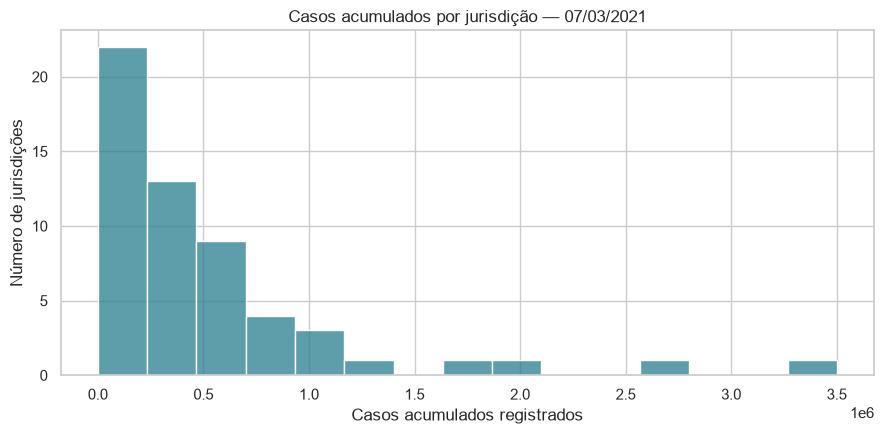

,casos_acumulados
count,56.00
mean,"513,508.73"
std,"648,036.40"
min,0.00
25%,"101,452.50"
50%,"334,675.00"
75%,"630,258.50"
max,"3,501,394.00"


In [16]:
fig, ax = plt.subplots(figsize=(9, 4.5))
sns.histplot(recorte_final["casos_acumulados"].dropna(), bins=15, color="#287c8e", ax=ax)
ax.set(title=f"Casos acumulados por jurisdição — {data_final:%d/%m/%Y}",
       xlabel="Casos acumulados registrados", ylabel="Número de jurisdições")
salvar_figura(fig, "01_histograma_casos.png")
display(recorte_final["casos_acumulados"].describe().to_frame("casos_acumulados"))

**Como interpretar:** compare média e mediana da saída. Se a média for maior, poucos totais altos podem estar puxando a média para cima. A assimetria é uma propriedade da amostra; não prova que algum estado mediu os dados incorretamente.

### 7.3. Contagem de registros por estado

Para uma variável categórica, faz sentido contar categorias. Cada barra mostra quantas datas a jurisdição possui. Cobertura desigual altera a interpretação de comparações de períodos inteiros.

Menor cobertura: 357 | Maior: 420


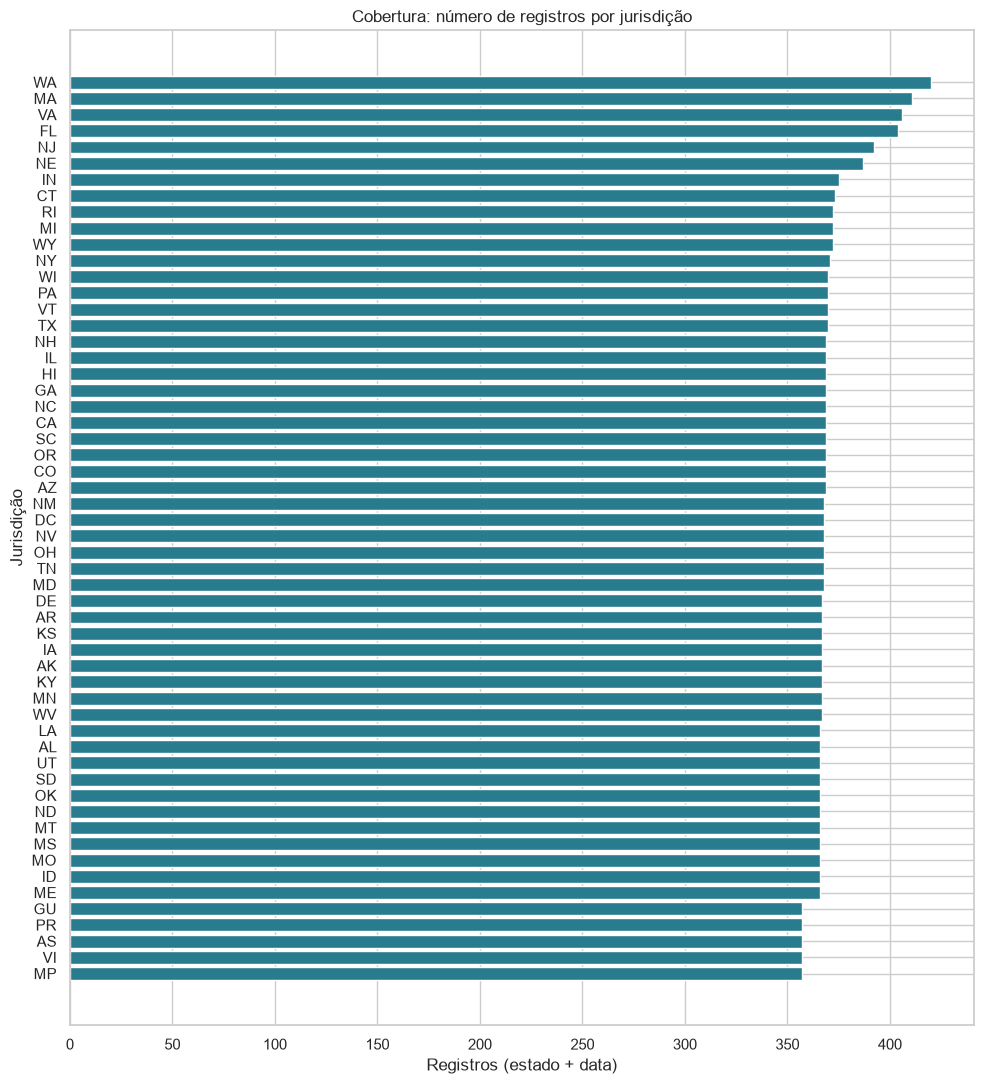

In [17]:
registros_por_estado = df.groupby("estado", observed=True).size().sort_values()
fig, ax = plt.subplots(figsize=(10, 11))
ax.barh(registros_por_estado.index.astype(str), registros_por_estado.values, color="#287c8e")
ax.set(title="Cobertura: número de registros por jurisdição", xlabel="Registros (estado + data)", ylabel="Jurisdição")
salvar_figura(fig, "02_cobertura_estados.png")
print("Menor cobertura:", int(registros_por_estado.min()), "| Maior:", int(registros_por_estado.max()))

**Como interpretar:** barras menores indicam menos datas disponíveis. A contagem sozinha não diz se faltam datas no início, no meio ou no fim. Veremos a cobertura por data antes de interpretar a evolução do conjunto.

### 7.4. Boxplot de óbitos acumulados

O **boxplot** resume uma distribuição. A linha interna marca a mediana; a caixa vai do primeiro ao terceiro quartil. Os pontos além dos bigodes são candidatos a valores atípicos pela regra de 1,5 vezes o intervalo interquartil.

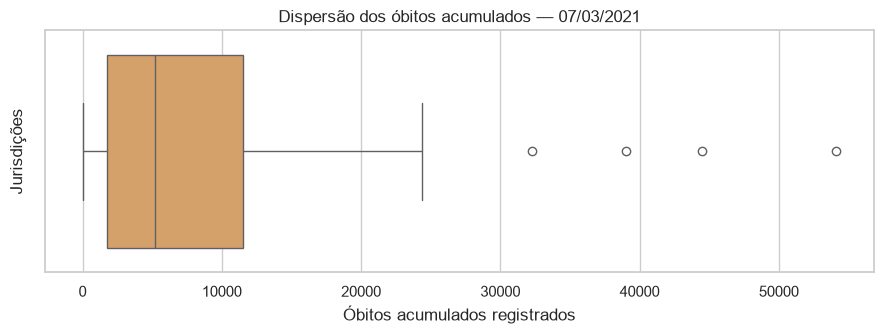

In [18]:
fig, ax = plt.subplots(figsize=(9, 3.5))
sns.boxplot(x=recorte_final["obitos_acumulados"].dropna(), color="#e6a15a", ax=ax)
ax.set(title=f"Dispersão dos óbitos acumulados — {data_final:%d/%m/%Y}",
       xlabel="Óbitos acumulados registrados", ylabel="Jurisdições")
salvar_figura(fig, "03_boxplot_obitos.png")

## 8. Investigar outliers com a regra do IQR

**Q1** deixa 25% dos valores abaixo dele; **Q3**, 75%. **IQR = Q3 − Q1** é a largura da parte central da distribuição. A regra sinaliza valores abaixo de Q1 − 1,5 × IQR ou acima de Q3 + 1,5 × IQR.

Ser sinalizado não significa ser errado. Jurisdições têm populações, períodos e formas de registro diferentes. **Decisão: preservar os candidatos a outlier**, mostrar quais são e não os classificar como erros sem investigar a origem.

In [19]:
serie_obitos = recorte_final["obitos_acumulados"].dropna()
q1, q3 = serie_obitos.quantile([0.25, 0.75])
iqr = q3 - q1
limite_inferior, limite_superior = q1 - 1.5 * iqr, q3 + 1.5 * iqr
candidatos_outlier = recorte_final.loc[
    recorte_final["obitos_acumulados"].lt(limite_inferior)
    | recorte_final["obitos_acumulados"].gt(limite_superior),
    ["estado", "data", "obitos_acumulados"],
].sort_values("obitos_acumulados", ascending=False)
print(f"Q1={q1:,.1f}; Q3={q3:,.1f}; IQR={iqr:,.1f}")
print(f"Limites: {limite_inferior:,.1f} a {limite_superior:,.1f}")
display(candidatos_outlier)
candidatos_outlier.to_csv(TABLES / "candidatos_outlier_obitos.csv", index=False)

Q1=1,778.8; Q3=11,512.2; IQR=9,733.5
Limites: -12,821.5 a 26,112.5


,estado,data,obitos_acumulados
2194,CA,2021-03-07,"54,124.00"
17751,TX,2021-03-07,"44,451.00"
14076,NY,2021-03-07,"39,029.00"
4075,FL,2021-03-07,"32,266.00"


## 9. Agrupar e resumir

### 9.1. groupby e agg: um resumo por estado

**groupby('estado')** separa a tabela em grupos. **agg** especifica qual resumo queremos de cada coluna. A nova tabela terá uma linha por estado, não por estado e dia.

**size** conta registros; **min/max** encontram a primeira/última data; **median** calcula a mediana; a soma de um indicador booleano conta quantas correções ocorreram. observed=True mantém apenas categorias observadas.

In [20]:
resumo_estados = df.groupby("estado", observed=True).agg(
    registros=("data", "size"),
    primeira_data=("data", "min"),
    ultima_data=("data", "max"),
    mediana_incremento_casos=("casos_incremento", "median"),
    revisoes_casos=("correcao_casos", "sum"),
    hospitalizacoes_informadas=("hospitalizados_atualmente", "count"),
)
resumo_estados["cobertura_hospitalizacao_pct"] = (
    100 * resumo_estados["hospitalizacoes_informadas"] / resumo_estados["registros"]
)
display(resumo_estados.head(10))
resumo_estados.to_csv(TABLES / "resumo_por_estado.csv")

,registros,primeira_data,ultima_data,mediana_incremento_casos,revisoes_casos,hospitalizacoes_informadas,cobertura_hospitalizacao_pct
estado,,,,,,,
AK,367,2020-03-06,2021-03-07,75.00,0,324,88.28
AL,366,2020-03-07,2021-03-07,"1,034.50",0,349,95.36
AR,367,2020-03-06,2021-03-07,662.00,1,351,95.64
AS,357,2020-03-16,2021-03-07,0.00,0,0,0.00
AZ,369,2020-03-04,2021-03-07,"1,132.00",0,329,89.16
CA,369,2020-03-04,2021-03-07,"4,810.00",0,346,93.77
CO,369,2020-03-04,2021-03-07,521.00,0,352,95.39
CT,373,2020-02-29,2021-03-07,203.00,2,351,94.10
DC,368,2020-03-05,2021-03-07,85.00,0,323,87.77


### 9.2. Construir o resumo diário e medir a cobertura

Para a série do conjunto, somamos **incrementos de estados diferentes no mesmo dia**. Ao somar hospitalizações, obtemos pessoas hospitalizadas naquele dia nas jurisdições que informaram dados; esse total pode ter cobertura parcial.

As contagens de cobertura são indispensáveis. Se só alguns estados estavam presentes no início, uma soma menor pode refletir ausência de dados. Para comparar casos e óbitos ao longo do tempo, exigiremos registros das 56 jurisdições e incrementos conhecidos.

**asfreq('D')** explicita dias sem registros, caso existam, sem inventar valores. A função lambda dentro de agg é uma forma curta de pedir soma com pelo menos um valor conhecido.

In [21]:
numero_jurisdicoes = int(df["estado"].nunique())
diario = df.groupby("data", observed=True).agg(
    casos_liquidos=("casos_incremento", lambda s: s.sum(min_count=1)),
    obitos_liquidos=("obitos_incremento", lambda s: s.sum(min_count=1)),
    hospitalizados_reportados=("hospitalizados_atualmente", lambda s: s.sum(min_count=1)),
    jurisdicoes=("estado", "nunique"),
    casos_informados=("casos_incremento", "count"),
    obitos_informados=("obitos_incremento", "count"),
    hospitalizacoes_informadas=("hospitalizados_atualmente", "count"),
).sort_index().asfreq("D")
diario["cobertura_completa"] = (
    diario["jurisdicoes"].eq(numero_jurisdicoes)
    & diario["casos_informados"].eq(numero_jurisdicoes)
    & diario["obitos_informados"].eq(numero_jurisdicoes)
)
diario_completo = diario.loc[diario["cobertura_completa"]].copy()
print("Dias na base:", len(diario), "| Dias com cobertura completa:", len(diario_completo))
print("Período completo:", diario_completo.index.min().date(), "a", diario_completo.index.max().date())
display(diario.tail())
diario.to_csv(TABLES / "resumo_diario.csv")

Dias na base: 420 | Dias com cobertura completa: 357
Período completo: 2020-03-16 a 2021-03-07


,casos_liquidos,obitos_liquidos,hospitalizados_reportados,jurisdicoes,casos_informados,obitos_informados,hospitalizacoes_informadas,cobertura_completa
data,,,,,,,,
2021-03-03,66836,2449,"45,462.00",56,56,56,53,True
2021-03-04,65487,1743,"44,172.00",56,56,56,53,True
2021-03-05,68787,2221,"42,541.00",56,56,56,53,True
2021-03-06,60015,1680,"41,401.00",56,56,56,53,True
2021-03-07,41835,842,"40,199.00",56,56,56,53,True


**Atenção ao significado:** “cobertura completa” indica presença das jurisdições e dos campos escolhidos, não ausência de subnotificação nem igualdade dos critérios de registro. Hospitalizações têm sua própria cobertura, mostrada separadamente.

### 9.3. Totais mensais sem comparar um mês incompleto com um inteiro

Usamos apenas os dias com cobertura completa de casos e óbitos. Cada mês recebe uma contagem de dias observados e de dias esperados. Um mês parcial fica identificado e não entra na escolha do maior **mês completo**.

In [22]:
mensal = diario_completo.groupby(diario_completo.index.to_period("M")).agg(
    casos_liquidos=("casos_liquidos", "sum"),
    obitos_liquidos=("obitos_liquidos", "sum"),
    dias_observados=("casos_liquidos", "size"),
)
mensal["dias_no_mes"] = mensal.index.days_in_month
mensal["mes_completo"] = mensal["dias_observados"].eq(mensal["dias_no_mes"])
mensal.index.name = "mes"
display(mensal)
mensal.to_csv(TABLES / "resumo_mensal.csv")

,casos_liquidos,obitos_liquidos,dias_observados,dias_no_mes,mes_completo
mes,,,,,
2020-03,191218,4251,16,31,False
2020-04,876279,55315,30,30,True
2020-05,718205,41137,31,31,True
2020-06,831597,19475,30,30,True
2020-07,1900180,25249,31,31,True
2020-08,1457213,30244,31,31,True
2020-09,1192663,23329,30,30,True
2020-10,1892015,23545,31,31,True
2020-11,4475991,37065,30,30,True


### 9.4. pivot_table: cruzar mês e estado

Uma **tabela dinâmica** tem grupos nas linhas e nas colunas. Aqui: meses nas linhas, estados nas colunas e soma dos incrementos líquidos nas células.

Não passamos fill_value=0: uma combinação ausente não deve virar um zero inventado. A tabela completa é salva; mostramos uma parte para facilitar a leitura. Os meses parciais continuam identificados na tabela mensal anterior.

In [23]:
base_periodo_completo = df.loc[df["data"].isin(diario_completo.index)]
pivot_mensal = base_periodo_completo.pivot_table(
    index="mes", columns="estado", values="casos_incremento",
    aggfunc=lambda s: s.sum(min_count=1), observed=True,
)
display(pivot_mensal.iloc[-5:, :10])
pivot_mensal.to_csv(TABLES / "pivot_casos_mes_estado.csv")

estado,AK,AL,AR,AS,AZ,CA,CO,CT,DC,DE
mes,,,,,,,,,,
2020-11,16011,57239,45169,0,80871,290963,125555,46088,4286,10703
2020-12,14138,111702,67779,0,193390,1032411,101192,68413,7431,21802
2021-01,7137,98413,70130,0,238197,997969,62082,64315,7889,20615
2021-02,3391,33613,27147,0,58378,232214,32124,29923,3726,8728
2021-03,897,6567,2403,0,9672,25832,8299,5384,821,1555


## 10. Análise bivariada — relacionar duas variáveis

### 10.1. Estado × casos acumulados na mesma data

O ranking responde à pergunta de **volume**. nlargest seleciona os dez maiores valores. Depois ordenamos para que a maior barra horizontal fique no topo.

Os rótulos são siglas oficiais: CA = Califórnia; TX = Texas; FL = Flórida; NY = Nova York. Não temos denominadores populacionais para produzir um ranking de risco por habitante.

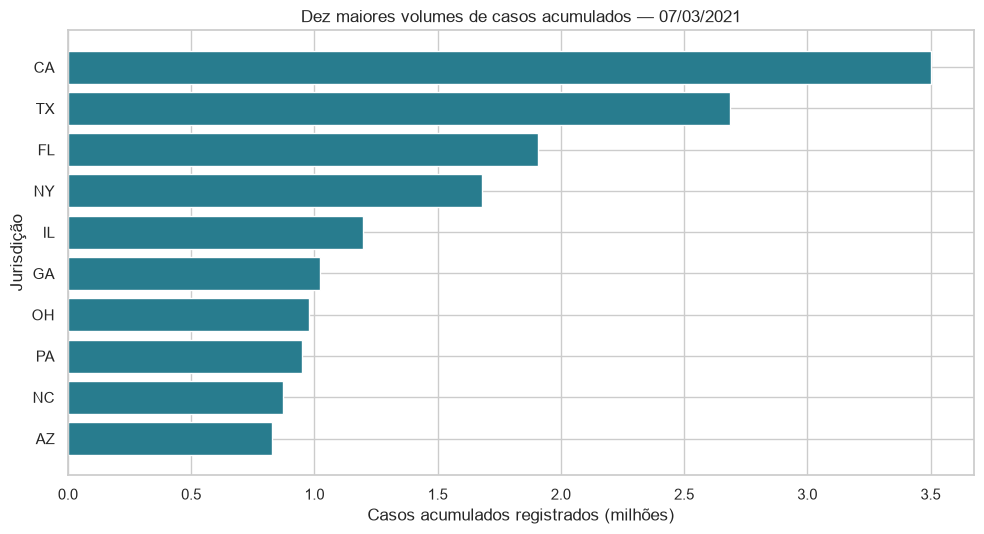

,estado,casos_acumulados,obitos_acumulados
2194,CA,"3,501,394.00","54,124.00"
17751,TX,"2,686,818.00","44,451.00"
4075,FL,"1,909,209.00","32,266.00"
14076,NY,"1,681,169.00","39,029.00"
6272,IL,"1,198,335.00","23,014.00"
4444,GA,"1,023,487.00","17,906.00"
14444,OH,"978,471.00","17,656.00"
15549,PA,"948,643.00","24,349.00"
11455,NC,"872,176.00","11,502.00"
1825,AZ,"826,454.00","16,328.00"


In [24]:
top10 = recorte_final.nlargest(10, "casos_acumulados").sort_values("casos_acumulados")
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top10["estado"].astype(str), top10["casos_acumulados"] / 1_000_000, color="#287c8e")
ax.set(title=f"Dez maiores volumes de casos acumulados — {data_final:%d/%m/%Y}",
       xlabel="Casos acumulados registrados (milhões)", ylabel="Jurisdição")
salvar_figura(fig, "04_ranking_casos.png")
display(top10[["estado", "casos_acumulados", "obitos_acumulados"]].sort_values("casos_acumulados", ascending=False))

### 10.2. Casos acumulados × óbitos acumulados

Cada ponto do gráfico de **dispersão** é uma jurisdição na data final. O eixo X mostra casos; o Y, óbitos. Se os pontos tendem a subir da esquerda para a direita, existe associação positiva.

**A associação não mede causalidade nem a probabilidade individual de morrer.** População, detecção de casos, período de exposição e critérios de notificação afetam os dois totais. Não usamos a divisão simples óbitos/casos como “risco individual”.

Jurisdições com as duas medidas conhecidas: 56


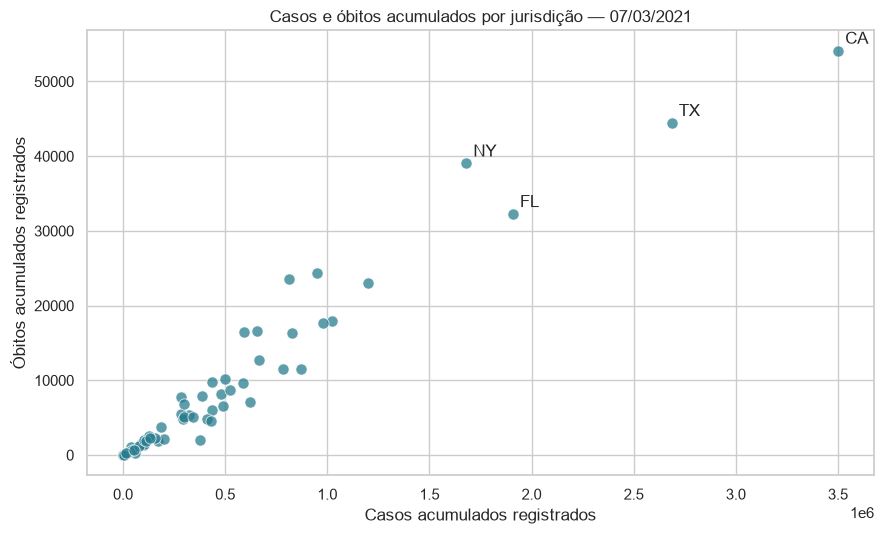

In [25]:
pares = recorte_final.dropna(subset=["casos_acumulados", "obitos_acumulados"])
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.scatterplot(data=pares, x="casos_acumulados", y="obitos_acumulados",
                s=65, alpha=0.75, color="#287c8e", ax=ax)
for _, linha in pares.nlargest(4, "casos_acumulados").iterrows():
    ax.annotate(str(linha["estado"]), (linha["casos_acumulados"], linha["obitos_acumulados"]),
                xytext=(5, 5), textcoords="offset points")
ax.set(title=f"Casos e óbitos acumulados por jurisdição — {data_final:%d/%m/%Y}",
       xlabel="Casos acumulados registrados", ylabel="Óbitos acumulados registrados")
salvar_figura(fig, "05_dispersao_casos_obitos.png")
print("Jurisdições com as duas medidas conhecidas:", len(pares))

## 11. Data × registros diários — a terceira relação

Uma linha temporal mostra como uma variável muda de uma data para outra. Vamos mostrar casos e óbitos em **painéis separados**, porque têm escalas diferentes.

A linha fina representa o incremento líquido registrado no dia, incluindo revisões. Como apoio à leitura, a linha grossa usa a **média móvel dos últimos sete dias**: soma sete observações e divide por sete. Não usa dados futuros nem representa uma previsão. Exigimos sete dias completos; lacunas ficam como nulos.

Não interpretaremos a distância entre picos como tempo entre infecção e morte: datas de notificação e revisões não permitem essa conclusão.

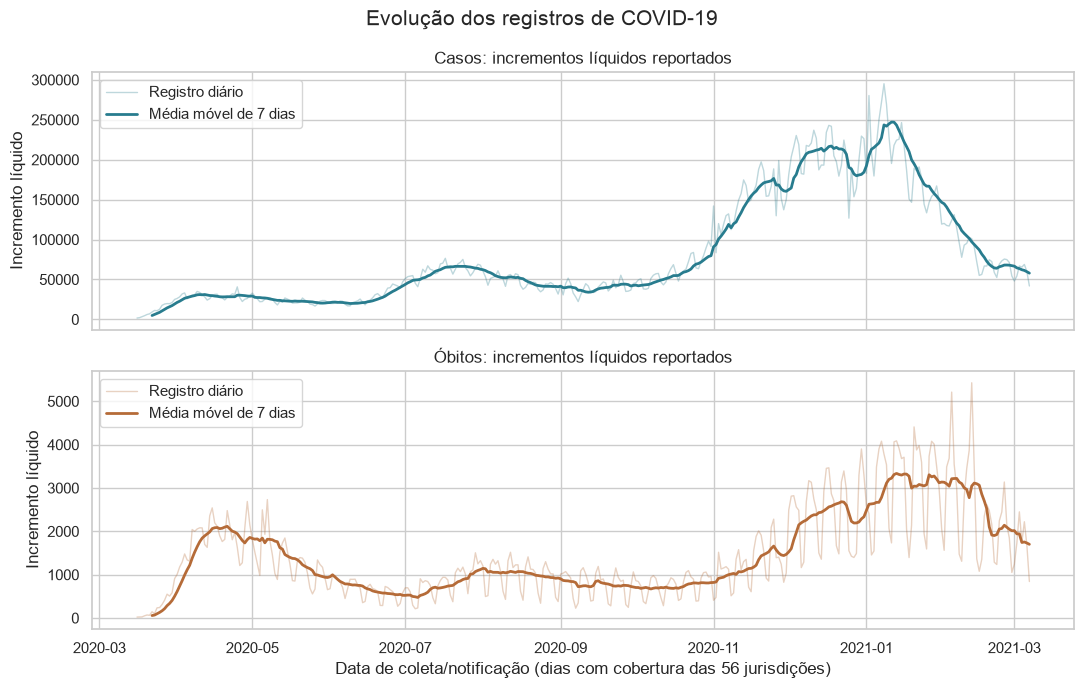

In [26]:
serie_tempo = diario[["casos_liquidos", "obitos_liquidos"]].where(diario["cobertura_completa"])
media_7dias = serie_tempo.rolling(window=7, min_periods=7).mean()

fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)
for ax, coluna, titulo, cor in [
    (axes[0], "casos_liquidos", "Casos: incrementos líquidos reportados", "#287c8e"),
    (axes[1], "obitos_liquidos", "Óbitos: incrementos líquidos reportados", "#b56b38"),
]:
    ax.plot(serie_tempo.index, serie_tempo[coluna], color=cor, alpha=0.30, linewidth=1, label="Registro diário")
    ax.plot(media_7dias.index, media_7dias[coluna], color=cor, linewidth=2, label="Média móvel de 7 dias")
    ax.set(title=titulo, ylabel="Incremento líquido")
    ax.legend(loc="upper left")
axes[1].set_xlabel("Data de coleta/notificação (dias com cobertura das 56 jurisdições)")
fig.suptitle("Evolução dos registros de COVID-19", fontsize=15)
salvar_figura(fig, "06_evolucao_temporal.png")

### 11.1. Quantificar o que o gráfico mostra

idxmax retorna a **data** do maior valor; max retorna o próprio valor. Avaliamos os dias com cobertura completa. O maior valor diário pode ter sido influenciado por acúmulo de notificações e correções.

Para comparar meses, selecionamos somente os completos. Março de 2021 termina no dia 7, então sua soma não representa o mês inteiro.

In [27]:
pico_casos_data = diario_completo["casos_liquidos"].idxmax()
pico_obitos_data = diario_completo["obitos_liquidos"].idxmax()
meses_completos = mensal.loc[mensal["mes_completo"]]
mes_maior = meses_completos["casos_liquidos"].idxmax()
print(f"Maior incremento de casos: {diario_completo.loc[pico_casos_data, 'casos_liquidos']:,.0f} em {pico_casos_data:%d/%m/%Y}")
print(f"Maior incremento de óbitos: {diario_completo.loc[pico_obitos_data, 'obitos_liquidos']:,.0f} em {pico_obitos_data:%d/%m/%Y}")
print(f"Mês completo com mais incrementos de casos: {mes_maior} ({mensal.loc[mes_maior, 'casos_liquidos']:,.0f})")

Maior incremento de casos: 295,121 em 08/01/2021
Maior incremento de óbitos: 5,427 em 12/02/2021
Mês completo com mais incrementos de casos: 2020-12 (6,323,266)


### 11.2. Cobertura das hospitalizações

Um total hospitalar pode variar porque o número de pacientes mudou, porque mais estados passaram a informar ou por ambos. Mostrar apenas a soma esconderia esse problema.

O gráfico abaixo separa **presença de uma linha** de **presença do indicador hospitalar**. A linha de referência mostra o total de jurisdições. Esse controle sustenta a decisão de preservar nulos.

Sem hospitalização informada na data final: ['AS', 'MP', 'VI']


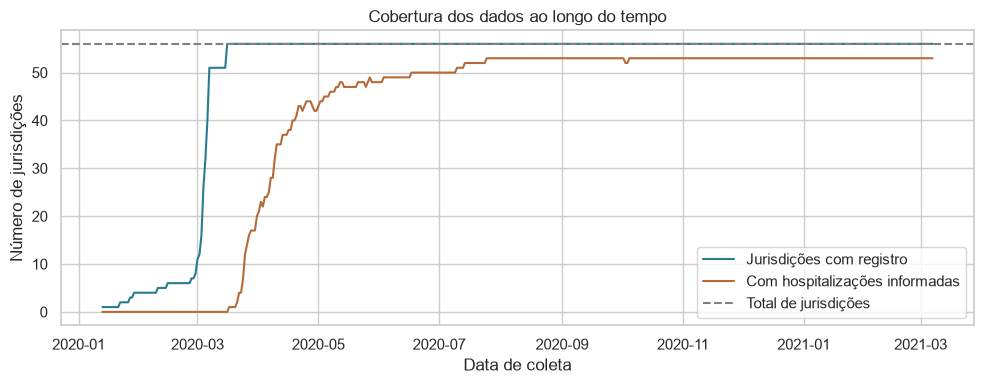

In [28]:
fig, ax = plt.subplots(figsize=(10, 4))
ax.plot(diario.index, diario["jurisdicoes"], label="Jurisdições com registro", color="#287c8e")
ax.plot(diario.index, diario["hospitalizacoes_informadas"], label="Com hospitalizações informadas", color="#b56b38")
ax.axhline(numero_jurisdicoes, color="gray", linestyle="--", label="Total de jurisdições")
ax.set(title="Cobertura dos dados ao longo do tempo", xlabel="Data de coleta", ylabel="Número de jurisdições")
ax.legend()
salvar_figura(fig, "07_cobertura_temporal.png")
print("Sem hospitalização informada na data final:", recorte_final.loc[
    recorte_final["hospitalizados_atualmente"].isna(), "estado"
].astype(str).tolist())

### 11.3. Ler a tabela dinâmica como um mapa de calor

Um **heatmap** transforma valores em intensidades de cor. Aqui comparamos os cinco maiores volumes finais, usando apenas meses completos. As células representam incrementos líquidos mensais, não totais acumulados.

Cores mais intensas significam maior volume registrado. Isso não normaliza por população, nem corrige diferenças de duração entre meses.

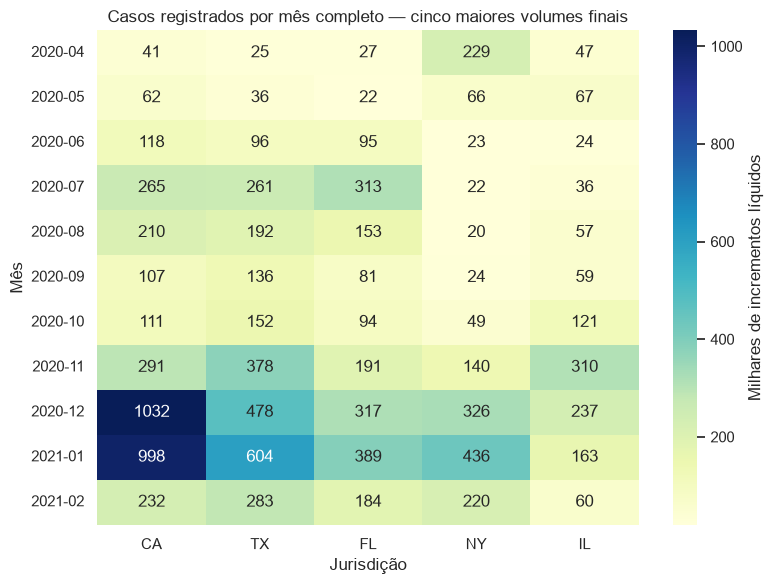

In [29]:
estados_top5 = recorte_final.nlargest(5, "casos_acumulados")["estado"].astype(str).tolist()
meses_validos = meses_completos.index.astype(str)
heatmap_mensal = pivot_mensal.loc[meses_validos, estados_top5] / 1000
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(heatmap_mensal, annot=True, fmt=".0f", cmap="YlGnBu",
            cbar_kws={"label": "Milhares de incrementos líquidos"}, ax=ax)
ax.set(title="Casos registrados por mês completo — cinco maiores volumes finais",
       xlabel="Jurisdição", ylabel="Mês")
salvar_figura(fig, "08_heatmap_mensal.png")

## 12. Matriz de correlação e interpretação

A **correlação de Pearson** resume uma associação linear e varia de −1 a +1. Valores perto de +1 indicam que as duas medidas tendem a aumentar juntas; perto de −1, a variar em sentidos contrários. Perto de zero significa pouca associação **linear**, não ausência de qualquer relação.

Usamos uma linha por jurisdição na mesma data, evitando misturar centenas de observações repetidas de cada estado. A diagonal sempre vale 1 para variáveis que têm variação.

O pandas usa pares com valores conhecidos. Como hospitalizações têm nulos, o tamanho da amostra pode variar entre pares. A segunda tabela torna isso explícito. População e outros fatores não controlados limitam a interpretação.

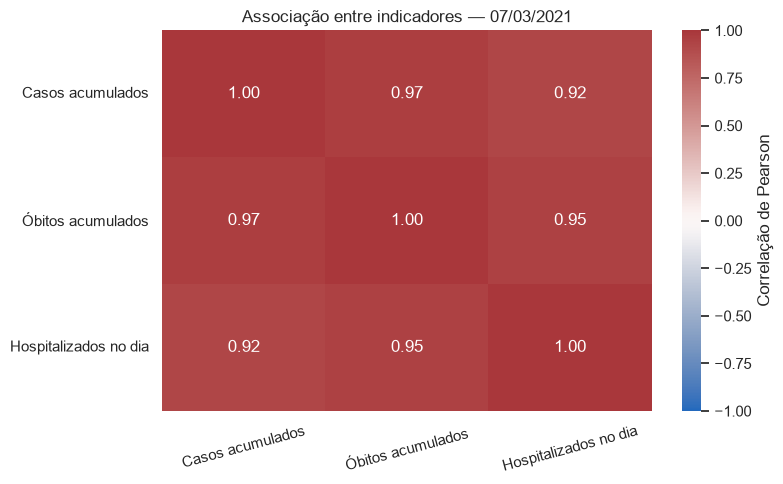

,Casos acumulados,Óbitos acumulados,Hospitalizados no dia
Casos acumulados,56,56,53
Óbitos acumulados,56,56,53
Hospitalizados no dia,53,53,53


In [30]:
variaveis_correlacao = ["casos_acumulados", "obitos_acumulados", "hospitalizados_atualmente"]
matriz_correlacao = recorte_final[variaveis_correlacao].corr(method="pearson", min_periods=3)
presenca = recorte_final[variaveis_correlacao].notna().astype(int)
quantidade_pares = presenca.T @ presenca

rotulos = ["Casos acumulados", "Óbitos acumulados", "Hospitalizados no dia"]
fig, ax = plt.subplots(figsize=(8, 5))
sns.heatmap(matriz_correlacao, annot=True, fmt=".2f", vmin=-1, vmax=1, center=0,
            cmap="vlag", xticklabels=rotulos, yticklabels=rotulos,
            cbar_kws={"label": "Correlação de Pearson"}, ax=ax)
ax.set_title(f"Associação entre indicadores — {data_final:%d/%m/%Y}")
ax.tick_params(axis="x", rotation=15)
salvar_figura(fig, "09_correlacao.png")
display(quantidade_pares.rename(index=dict(zip(variaveis_correlacao, rotulos)), columns=dict(zip(variaveis_correlacao, rotulos))))
matriz_correlacao.to_csv(TABLES / "correlacoes.csv")
quantidade_pares.to_csv(TABLES / "amostras_correlacoes.csv")

In [31]:
r_casos_obitos = float(matriz_correlacao.loc["casos_acumulados", "obitos_acumulados"])
display(Markdown(
    f"**Leitura do resultado:** casos e óbitos acumulados apresentam correlação "
    f"de Pearson **r = {r_casos_obitos:.3f}**, com **{len(pares)} jurisdições**. "
    "Há associação linear positiva forte nesta amostra. O resultado não identifica "
    "causas, não controla o tamanho da população e não representa uma taxa de letalidade. "
    "As correlações que envolvem hospitalização têm menos pares e combinam "
    "uma medida do dia com totais acumulados; são descrições, não estimativas de risco."
))

**Leitura do resultado:** casos e óbitos acumulados apresentam correlação de Pearson **r = 0.967**, com **56 jurisdições**. Há associação linear positiva forte nesta amostra. O resultado não identifica causas, não controla o tamanho da população e não representa uma taxa de letalidade. As correlações que envolvem hospitalização têm menos pares e combinam uma medida do dia com totais acumulados; são descrições, não estimativas de risco.

## 13. Responder às perguntas com evidências calculadas

Agora voltamos às perguntas formuladas no início. Os números do texto abaixo são gerados a partir das tabelas analisadas, para não depender de valores copiados manualmente.

Observe a diferença entre **resultado** (“CA tem o maior volume”) e **interpretação que exigiria mais dados** (“CA tem o maior risco”). Somente a primeira afirmação é sustentada por esta comparação.

In [32]:
total_casos = float(recorte_final["casos_acumulados"].sum(min_count=1))
total_obitos = float(recorte_final["obitos_acumulados"].sum(min_count=1))
top3 = recorte_final.nlargest(3, "casos_acumulados")
participacao_top3 = float(100 * top3["casos_acumulados"].sum() / total_casos)
ranking_texto = "; ".join(f"{linha.estado}: {linha.casos_acumulados:,.0f}" for linha in top3.itertuples())

conclusoes = f"""
### 1. Como evoluíram os registros?
A série tem oscilações e concentra altos volumes no fim de 2020 e início de 2021.
O maior incremento diário de casos registrado foi **{diario_completo.loc[pico_casos_data, 'casos_liquidos']:,.0f} em {pico_casos_data:%d/%m/%Y}**;
o de óbitos foi **{diario_completo.loc[pico_obitos_data, 'obitos_liquidos']:,.0f} em {pico_obitos_data:%d/%m/%Y}**.
O mês completo com mais incrementos de casos foi **{mes_maior}**, com **{mensal.loc[mes_maior, 'casos_liquidos']:,.0f}**.
São datas de registro, não necessariamente das ocorrências; não inferimos um atraso biológico entre esses picos.

### 2. Quais jurisdições concentraram mais casos na mesma data?
Em **{data_final:%d/%m/%Y}**, os três maiores volumes foram **{ranking_texto}**.
Juntos, representam **{participacao_top3:.1f}%** do acumulado conhecido de **{total_casos:,.0f} casos**.
O acumulado de óbitos na mesma data é **{total_obitos:,.0f}**.
Esses volumes não estão ajustados pela população e não definem um ranking de risco individual.

### 3. Existe associação entre casos e óbitos acumulados?
Sim: **r = {r_casos_obitos:.3f}**, para **{len(pares)} jurisdições** na data final.
A associação linear é positiva e forte nesta amostra. População, detecção e critérios de notificação
podem influenciar ambos os totais. Correlação não estabelece causalidade.

### 4. Que problemas limitam a leitura?
Não foram identificados duplicados exatos (**{duplicados_exatos}**).
Na base completa, faltam **{int(df['hospitalizados_atualmente'].isna().sum()):,}** valores de hospitalização.
Foram preservados **{int(correcoes['casos_incremento'])}** incrementos negativos de casos e
**{int(correcoes['obitos_incremento'])}** de óbitos.
A série temporal comparável de casos e óbitos usa **{len(diario_completo)} dias** com registros das
**{numero_jurisdicoes} jurisdições**. Março de 2021 é parcial e não entra no ranking de meses completos.
"""
display(Markdown(conclusoes))
(ROOT / "reports/conclusoes.md").write_text(conclusoes.strip() + "\n", encoding="utf-8")

Out[32]: 1508



### 1. Como evoluíram os registros?
A série tem oscilações e concentra altos volumes no fim de 2020 e início de 2021.
O maior incremento diário de casos registrado foi **295,121 em 08/01/2021**;
o de óbitos foi **5,427 em 12/02/2021**.
O mês completo com mais incrementos de casos foi **2020-12**, com **6,323,266**.
São datas de registro, não necessariamente das ocorrências; não inferimos um atraso biológico entre esses picos.

### 2. Quais jurisdições concentraram mais casos na mesma data?
Em **07/03/2021**, os três maiores volumes foram **CA: 3,501,394; TX: 2,686,818; FL: 1,909,209**.
Juntos, representam **28.2%** do acumulado conhecido de **28,756,489 casos**.
O acumulado de óbitos na mesma data é **515,151**.
Esses volumes não estão ajustados pela população e não definem um ranking de risco individual.

### 3. Existe associação entre casos e óbitos acumulados?
Sim: **r = 0.967**, para **56 jurisdições** na data final.
A associação linear é positiva e forte nesta amostra. População, detecção e critérios de notificação
podem influenciar ambos os totais. Correlação não estabelece causalidade.

### 4. Que problemas limitam a leitura?
Não foram identificados duplicados exatos (**0**).
Na base completa, faltam **3,441** valores de hospitalização.
Foram preservados **24** incrementos negativos de casos e
**73** de óbitos.
A série temporal comparável de casos e óbitos usa **357 dias** com registros das
**56 jurisdições**. Março de 2021 é parcial e não entra no ranking de meses completos.


### 13.1. O que recomendamos ao cliente

- Para avaliar **volume operacional**, considerar a concentração de registros e acompanhar a série diária com cobertura explícita.
- Para comparar **risco entre populações**, acrescentar denominadores populacionais em uma etapa futura e manter datas e definições comparáveis.
- Para monitorar hospitalizações, apresentar a disponibilidade do indicador junto com os valores; não transformar ausência em zero.
- Antes de tomar decisões sobre a situação atual, buscar uma fonte atualizada: este arquivo termina em março de 2021.

Estas recomendações dizem respeito à interpretação e à qualidade dos dados. O exercício é descritivo e não avalia causalidade, políticas públicas ou tratamentos.

## 14. Gerar a entrega executiva de duas páginas

O CEO não precisa ler cada célula. O relatório deve responder: **o que encontramos, por que isso importa e quais são os limites**.

Vamos salvar os principais resultados em JSON (um arquivo estruturado de chaves e valores). O script gerar_relatorio.py usa esse resumo e as figuras já produzidas para montar duas páginas em PDF. Ele não refaz nem altera a limpeza; apenas organiza a apresentação.

In [33]:
import json

resumo = {
    "linhas_brutas": int(linhas), "colunas_brutas": int(colunas),
    "jurisdicoes": numero_jurisdicoes,
    "data_inicial": df["data"].min().strftime("%Y-%m-%d"),
    "data_final": data_final.strftime("%Y-%m-%d"),
    "inicio_cobertura_completa": diario_completo.index.min().strftime("%Y-%m-%d"),
    "dias_cobertura_completa": len(diario_completo),
    "total_casos": total_casos, "total_obitos": total_obitos,
    "pico_casos_data": pico_casos_data.strftime("%Y-%m-%d"),
    "pico_casos_valor": int(diario_completo.loc[pico_casos_data, "casos_liquidos"]),
    "pico_obitos_data": pico_obitos_data.strftime("%Y-%m-%d"),
    "pico_obitos_valor": int(diario_completo.loc[pico_obitos_data, "obitos_liquidos"]),
    "mes_maior_casos": str(mes_maior),
    "mes_maior_casos_valor": int(mensal.loc[mes_maior, "casos_liquidos"]),
    "top3": [{"estado": str(r.estado), "casos": int(r.casos_acumulados)} for r in top3.itertuples()],
    "top3_participacao_pct": participacao_top3,
    "correlacao_casos_obitos": r_casos_obitos,
    "pares_casos_obitos": len(pares),
    "duplicados_exatos": duplicados_exatos,
    "colunas_mais_80_pct_nulos": int(qualidade_bruta["percentual_nulos"].gt(80).sum()),
    "nulos_hospitalizacao": int(df["hospitalizados_atualmente"].isna().sum()),
    "sem_hospitalizacao_final": recorte_final.loc[recorte_final["hospitalizados_atualmente"].isna(), "estado"].astype(str).tolist(),
    "correcoes_casos": int(correcoes["casos_incremento"]),
    "correcoes_obitos": int(correcoes["obitos_incremento"]),
    "correcoes_testes": int(correcoes["testes_incremento_referencia"]),
    "outliers_obitos": candidatos_outlier["estado"].astype(str).tolist(),
}
(ROOT / "reports/resumo_resultados.json").write_text(
    json.dumps(resumo, ensure_ascii=False, indent=2) + "\n", encoding="utf-8"
)
from gerar_relatorio import gerar_relatorio
caminho_relatorio = gerar_relatorio(ROOT)
print("Relatório gerado:", caminho_relatorio)

Relatório gerado: /private/tmp/eda-entrega-20261109-6nys_e8j/reports/relatorio_executivo.pdf


## 15. Conferir a entrega e consolidar o aprendizado

| Requisito | Evidência neste notebook |
|---|---|
| Inspeção inicial completa | Etapa 4 |
| Duplicados, tipos e nulos | Etapa 5 |
| Seleção/renomeação justificada | Etapas 5.3 e 5.5; CSV de decisões |
| Três variáveis univariadas | Etapa 7: casos, estado, óbitos |
| Outliers com decisão | Etapa 8 |
| groupby, agg, pivot_table | Etapa 9 |
| Três ou mais variáveis novas | Etapa 6: cinco variáveis |
| Três relações bivariadas | Etapas 10 e 11 |
| Pelo menos cinco visualizações | Nove arquivos em reports/figures |
| Tendências e correlação interpretada | Etapas 11 e 12 |
| Três perguntas respondidas | Etapa 13: quatro respostas |
| Relatório de 1 a 2 páginas | reports/relatorio_executivo.pdf |
| Instalação e reprodução | README.md e requirements.txt |

**Verificação final:** reinicie o kernel e execute todas as células. Depois confira se o PDF tem duas páginas e se você consegue explicar cada decisão sem apenas ler o código. O controle de versões deve ser concluído no seu repositório Git antes da entrega.

**Perguntas para você praticar:** por que não somamos acumulados de dias diferentes? Por que nulo não vira zero? Um outlier é sempre erro? O que muda se um mês só tem sete dias? O que uma correlação forte não permite concluir?

### Referências e transparência

- [Enunciado da Factoria F5](https://github.com/Factoria-F5-madrid/ai_project_EDA).
- [Dados oficiais do COVID Tracking Project](https://covidtracking.com/data/download/) e [definições das variáveis](https://covidtracking.com/about-data/data-definitions/).
- [Notebook da Elena Almansa Campos](https://github.com/elenaalmansacampos/ai_project_EDA/blob/main/notebooks/eda_covid19.ipynb), consultado como referência de organização. As decisões, cálculos e textos desta versão foram desenvolvidos para o nível médio e conferidos com o CSV oficial.

A versão de referência preenche alguns acumulados com o último valor conhecido. Aqui mantemos os nulos para não pressupor estabilidade durante a ausência. Também usamos uma data final comum e explicitamos cobertura e meses incompletos. São decisões metodológicas próprias, documentadas para que possam ser discutidas.